# Figure 1 — Make Panels

Generates abstract Figure 1 panels A–H (behaviour overview).
Based on: `notebooks/fig2_task_description_general_results.ipynb`

In [5]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import math
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy.stats import ttest_rel
from scipy.optimize import brentq
from matplotlib.ticker import FixedLocator

from adaptive_behavior import data_access, plotting
from adaptive_behavior.data_access import AddExtraColumns as Add
from adaptive_behavior.helpers import repo_root
from adaptive_behavior.style import apply_style, panel_fig, save_panel, PALETTE

color1, color2, color3 = "#d95f02", "#1b9e77", "#7570b3"
color_dict_label = {"90": color1, "60": color2, "0": color3}

S3_ROOT = "s3://aind-scratch-data/vr-foraging/vr-foraging-manuscript"
STORAGE_OPTIONS = {"skip_signature": "true"}
STAGES_CSV = "C:/git/aind-vr-foraging-paper/code/notebooks/results/sessions_stages.csv"

apply_style()
PANELS_DIR = repo_root() / "figures" / "fig1" / "panels"
PANELS_DIR.mkdir(parents=True, exist_ok=True)
print("Panels will be saved to:", PANELS_DIR)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Panels will be saved to: C:\git\cosyne2026_adaptive_behavior\figures\fig1\panels


In [6]:
EXCLUDED_SUBJECTS = {713578, 754575, 715866}

session_cat, valid_session_ids, macro_df = data_access.load_session_catalogue_and_sites(
    S3_ROOT, STORAGE_OPTIONS, EXCLUDED_SUBJECTS
)
macro_df = data_access.prepare_macro_df(
    macro_df,
    stage_filter=("data_collection", "control"),
    stages_csv=STAGES_CSV,
)
all_df = data_access.build_all_df(macro_df)
all_df = all_df[all_df["site_label"] == "RewardSite"].copy()
print(f"Loaded {all_df['mouse'].nunique()} mice, {all_df['session_id'].nunique()} sessions")


Loaded 24 mice, 712 sessions


## Panel B — Ethogram (raster with velocity)

Example session: behavior_754580_2024-10-15_09-20-17


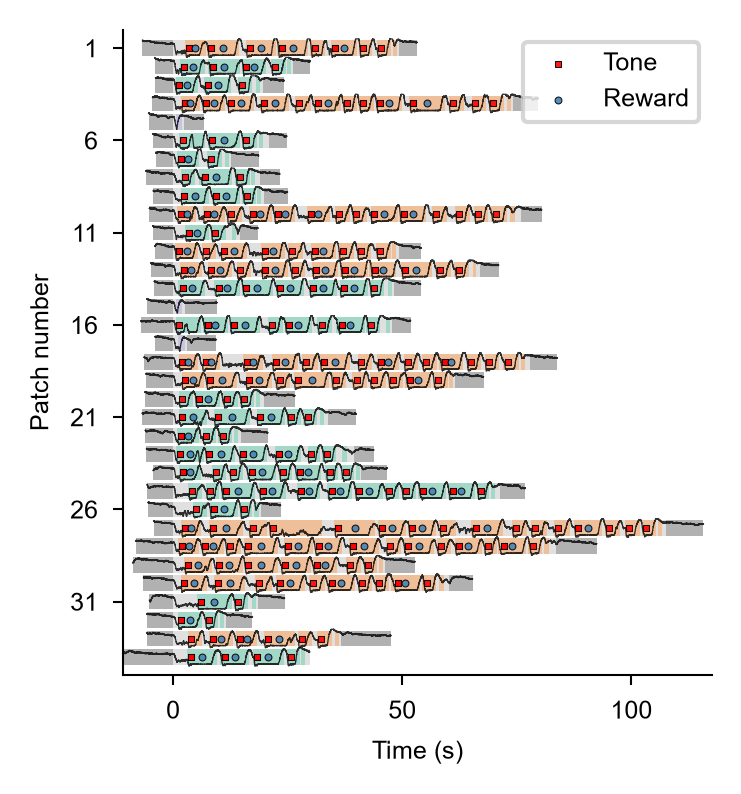

In [7]:
# --- Panel A: Ethogram (raster with velocity) ---
# Pick first available session from macro_df; override here if desired
example_session_id = "behavior_754580_2024-10-15_09-20-17"
print("Example session:", example_session_id)

# Load velocity
session_path = data_access.get_s3_location(example_session_id, S3_ROOT, STORAGE_OPTIONS)
pos_vel = (
    pl.read_parquet(
        f"{session_path}/position_velocity.parquet",
        storage_options=STORAGE_OPTIONS,
    )
    .to_pandas()
    .rename(columns={"Time": "times"})
)
vel_df = pos_vel[["times", "velocity"]].copy()

# Load all epoch types (InterSite, InterPatch, RewardSite) for this session
raw_epochs = (
    pl.scan_parquet(f"{S3_ROOT}/sites.parquet", storage_options=STORAGE_OPTIONS)
    .filter(pl.col("session_id") == example_session_id)
    .collect()
    .to_pandas()
)
# Add cumulative counters, patch onset, etc.
all_epochs = Add(raw_epochs).all_epochs
# Relabel patch tiers so color_dict_label keys match
all_epochs = data_access.prepare_macro_df(all_epochs, stages_csv=STAGES_CSV)

# Filter to a readable patch window (patch_index 6-40)
plot_df = all_epochs.loc[
    (all_epochs["patch_index"] >= 6) & (all_epochs["patch_index"] < 40)
].copy()
plot_df["patch_index"] = plot_df["patch_index"] - plot_df["patch_index"].min()

fig, ax = panel_fig("fig1_B")
apply_style()
plotting.raster_with_velocity(
    plot_df,
    vel_df,
    color_dict_label=color_dict_label,
    figsize=(fig, ax),
    bar_alpha=0.4,
)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Patch number")
sns.despine(ax=ax)
save_panel(fig, PANELS_DIR / "fig1_B.pdf")


## Panel C — P(stop) at first site

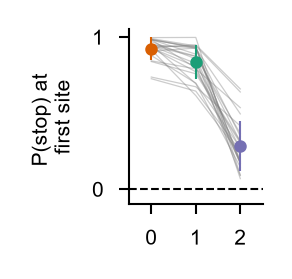

In [ ]:
# --- Panel B: P(stop) at first site by patch type ---
pre_df = (
    macro_df[
        (macro_df["site_label"] == "RewardSite")
        & (macro_df["site_index_in_patch_by_type"] == 0)
        & (macro_df["patch_index"] <= 40)
        & (macro_df["stage_name"].isin(["control", "data_collection"]))
    ]
    .groupby(["mouse", "session_id", "patch_label"])
    .agg({"has_choice": "mean"})
    .reset_index()
)
plot = pre_df.groupby(["mouse", "patch_label"])["has_choice"].mean().reset_index()

order = ["90", "60", "0"]
x_positions = {label: i for i, label in enumerate(order)}
colors_b = {"90": color1, "60": color2, "0": color3}

fig, ax = panel_fig("fig1_C")
for mouse, group in plot.groupby("mouse"):
    group = group.set_index("patch_label").reindex(order)
    xs = [x_positions[l] for l in order if l in group.index and not pd.isna(group.loc[l, "has_choice"])]
    ys = [group.loc[l, "has_choice"] for l in order if l in group.index and not pd.isna(group.loc[l, "has_choice"])]
    ax.plot(xs, ys, color="gray", alpha=0.4)

for label in order:
    subset = plot[plot["patch_label"] == label]["has_choice"]
    ax.errorbar(
        x_positions[label], subset.mean(), yerr=subset.std(),
        fmt="o", color=colors_b[label],
        capsize=0, capthick=0, elinewidth=0.5, markersize=2, zorder=3,
    )

ax.axhline(0, color="k", linestyle="--", linewidth=0.5)
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["High", "Low", "Null"], rotation=45)
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(-0.1, 1.05)
ax.set_yticks([0, 1])
ax.set_xlabel("")
ax.set_ylabel("P(stop) at \nfirst site")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
save_panel(fig, PANELS_DIR / "fig1_C.pdf")
# print("Saved fig1_C.pdf")


## Panel D

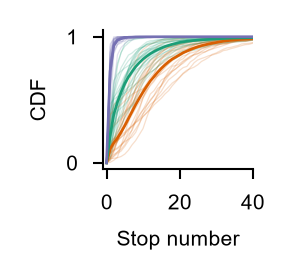

In [35]:
# --- Panel D: CDF of stop number per patch ---
pre_df = all_df[all_df["patch_index"] <= 50].copy()
plot_raw = (
    pre_df.groupby(["mouse", "session_id", "patch_index", "patch_label"])
    ["site_index_in_patch_by_type"].max()
    .reset_index()
)
palette = {"0": color3, "60": color2, "90": color1}
x_vals = np.arange(-0.1, 40, 1)

records = []
for (mouse, label), grp in plot_raw.groupby(["mouse", "patch_label"]):
    cdf = np.mean(grp["site_index_in_patch_by_type"].values[:, None] <= x_vals, axis=0)
    for x, y in zip(x_vals, cdf):
        records.append({"mouse": mouse, "patch_label": label, "x": x, "cdf": y})
cdf_df = pd.DataFrame(records)

fig, ax = panel_fig("fig1_D")
for (mouse, label), grp in cdf_df.groupby(["mouse", "patch_label"]):
    ax.plot(grp["x"], grp["cdf"], color=palette[label], alpha=0.2, linewidth=0.3)

sns.lineplot(
    data=cdf_df, x="x", y="cdf",
    hue="patch_label", hue_order=["90", "60", "0"],
    palette=palette, ax=ax, errorbar=None, linewidth=0.65, legend=False,
)
ax.set_xlim(-1, 40)
ax.set_yticks(np.arange(0, 1.1,1))
ax.set_yticklabels(["0","1"])
ax.set_xlabel("Stop number")
ax.set_ylabel("CDF")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
save_panel(fig, PANELS_DIR / "fig1_D.pdf")


## Velocity panels C, E, G — shared data collection

This cell performs one S3 pass to collect velocity snippets for all three
velocity panels. Re-run only if the session list or filter criteria change.
Individual panel cells can be re-run independently after this.

In [ ]:
# --- Shared velocity collection for panels C, E, G ---
# Runs one S3 pass over all sessions; re-run if data or filters change.
base = all_df[
    (all_df["patch_label"].isin(["60", "90", "0"]))
    & (all_df["patch_index"] <= 50)
]

criteria = {
    "enter_first": base[(base["has_choice"] == 1)],
}

all_sessions = set().union(*(set(df["session_id"]) for df in criteria.values()))
results = {k: [] for k in criteria}

for session_id in sorted(all_sessions):
    try:
        session_path = data_access.get_s3_location(session_id, S3_ROOT, STORAGE_OPTIONS)
        vel = (
            pl.read_parquet(
                f"{session_path}/position_velocity.parquet",
                storage_options=STORAGE_OPTIONS,
            )
            .to_pandas()
            .rename(columns={"Time": "times"})[["times", "velocity"]]
        )
    except Exception as e:
        print(f"  velocity load failed for {session_id}: {e}")
        continue

    for key, base_df in criteria.items():
        df = base_df[base_df["session_id"] == session_id].copy()
        if df.empty:
            continue
        try:
            ts = plotting.trial_collection(df, vel, aligned="start_time", window=[-1, 4])
            group_cols = ["times", "mouse", "patch_label", "session_id"]
            if key == "stop_first_site":
                group_cols.append("has_reward")  # keep outcome for rewarded vs omission
            ts = (
                ts.groupby(group_cols)
                .velocity.mean()
                .reset_index()
            )
            results[key].append(ts)
        except Exception as e:
            print(f"  {key} failed for {session_id}: {e}")

vel_dfs = {k: pd.concat(v, ignore_index=True) for k, v in results.items() if v}
for k, df in vel_dfs.items():
    df["times"] = df["times"].round(2)
    print(f"  {k}: {len(df)} rows, {df['mouse'].nunique()} mice")


## Panel E — Velocity at first-site odor onset

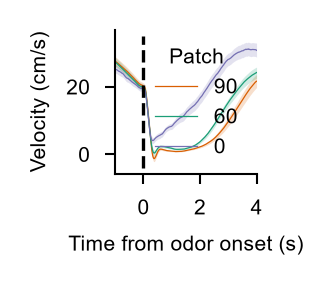

In [ ]:
# --- Panel C: Velocity at first-site odor onset ---
palette = {"90": color1, "60": color2, "0": color3}
key = "enter_first"
if key not in vel_dfs:
    raise RuntimeError("Run velocity collection cell first")

plot = (
    vel_dfs[key]
    .groupby(["mouse", "times", "patch_label"])
    .velocity.mean()
    .reset_index()
)

fig, ax = panel_fig("fig1_E")
sns.lineplot(
    data=plot, x="times", y="velocity",
    hue="patch_label", hue_order=["90", "60", "0"],
    palette=palette, estimator="mean", errorbar="se",
    err_kws={"linewidth": 0}, legend=True, ax=ax,
)
y0, y1 = ax.get_ylim()
ax.vlines(0, y0, y1, color="k", linestyle="--", linewidth=0.8)
ax.set_xlim(-1, 4)
ax.set_xlabel("Time from odor onset (s)")
ax.set_ylabel("Velocity (cm/s)")
if ax.get_legend():
    ax.legend(title="Patch", fontsize=5, frameon=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
save_panel(fig, PANELS_DIR / "fig1_E.pdf")


## Panel F — P(leave) by consecutive omissions

In [12]:
# --- Panel F: P(leave) by consecutive omissions ---
plot = (
    all_df.loc[
        (all_df["cumulative_rewards"] == 0)
        & (all_df["consecutive_failures"] != 0)
        & (all_df["consecutive_failures"] <= 2)
        & (all_df["patch_label"].isin(["60", "90"]))
    ]
    .groupby(["mouse", "patch_label", "consecutive_failures"])
    .agg({"has_choice": "mean"})
    .reset_index()
)
plot["leave_probability"] = 1 - plot["has_choice"]

wide = plot.pivot_table(
    index=["mouse", "consecutive_failures"],
    columns="patch_label",
    values="leave_probability",
).reset_index()
wide["60"] = wide["60"].astype(float)
wide["90"] = wide["90"].astype(float)

pvals = {}
for cf, sub in wide.groupby("consecutive_failures"):
    sub = sub.dropna(subset=["60", "90"])
    if len(sub) > 1:
        _, p = ttest_rel(sub["60"], sub["90"])
        pvals[cf] = p
    else:
        pvals[cf] = float("nan")

cf_list = [1, 2]
plot_sub = plot[plot["consecutive_failures"].isin(cf_list)]
wide_sub = wide[wide["consecutive_failures"].isin(cf_list)]

fig, ax = panel_fig("fig1_F")
hue_order = ["90", "60"]
palette_f = {"90": color1, "60": color2}
x_ticks = sorted(plot_sub["consecutive_failures"].unique())
tick_to_int = {v: i for i, v in enumerate(x_ticks)}
offsets = np.linspace(-0.25, 0.25, 2)
hue_offset = {hue: offsets[i] for i, hue in enumerate(hue_order)}
x_lim = (-0.5, len(x_ticks) - 1 + 0.5)

for _, mouse_row in wide_sub.iterrows():
    for cf in x_ticks:
        row = wide_sub[
            (wide_sub["mouse"] == mouse_row["mouse"])
            & (wide_sub["consecutive_failures"] == cf)
        ]
        if row.empty:
            continue
        xs = [tick_to_int[cf] + hue_offset[h] for h in hue_order if not pd.isna(row[h].values[0])]
        ys = [row[h].values[0] for h in hue_order if not pd.isna(row[h].values[0])]
        if len(xs) == 2:
            ax.plot(xs, ys, color="gray", alpha=0.4, linewidth=0.5, zorder=5)

for hue in hue_order:
    for cf in x_ticks:
        subset = plot_sub[
            (plot_sub["consecutive_failures"] == cf) & (plot_sub["patch_label"] == hue)
        ]["leave_probability"]
        if subset.empty:
            continue
        x_pos = tick_to_int[cf] + hue_offset[hue]
        ax.errorbar(
            x_pos, subset.mean(), yerr=subset.sem(),
            fmt="o", color=palette_f[hue],
            capsize=0, capthick=0, elinewidth=0.8, zorder=10,
            label=hue if cf == x_ticks[0] else "",
        )

bracket_h, y_pad = 0.05, 0.08
for cf, p in {k: v for k, v in pvals.items() if k in cf_list}.items():
    if pd.isna(p):
        continue
    sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
    xi = tick_to_int[cf]
    x1, x2 = xi + hue_offset["90"], xi + hue_offset["60"]
    y_top = plot_sub.loc[plot_sub["consecutive_failures"] == cf, "leave_probability"].max()
    y_bar = y_top + y_pad
    ax.plot([x1, x1, x2, x2], [y_bar, y_bar + bracket_h, y_bar + bracket_h, y_bar], color="black")
    ax.text((x1 + x2) / 2, y_bar + bracket_h, sig, ha="center", va="bottom")

ax.set_xticks(range(len(x_ticks)))
ax.set_xticklabels([int(x) for x in x_ticks])
ax.set_xlim(x_lim)
ax.set_ylim(-0.05, 1.3)
ax.set_yticks([0, 0.5, 1])
ax.set_xlabel("Consecutive reward omissions")
ax.set_ylabel("P(leave)")
ax.hlines(0, x_lim[0], x_lim[1], colors="grey", linestyles="dashed")
sns.despine(ax=ax)
plt.tight_layout()
save_panel(fig, PANELS_DIR / "fig1_F.pdf")
print("Saved fig1_F.pdf")


Saved fig1_F.pdf


## Panel G — Velocity at first-site stops (rewarded vs omission)

In [ ]:
# --- Panel G: Velocity at first-site stops, rewarded vs omission ---
palette = {"90": color1, "60": color2, "0": color3}
hue_order = ["90", "60", "0"]
reward_names = {"1": "Reward", "1.0": "Reward", "True": "Reward",
                "0": "Omission", "0.0": "Omission", "False": "Omission"}
key = "stop_first_site"
if key not in vel_dfs:
    raise RuntimeError("Run velocity collection cell first")

plot = (
    vel_dfs[key]
    .groupby(["mouse", "times", "patch_label", "has_reward"])
    .velocity.mean()
    .reset_index()
)
plot = plot[plot["patch_label"].isin(hue_order)]

fig, ax = panel_fig("fig1_G")
sns.lineplot(
    data=plot, x="times", y="velocity",
    hue="patch_label", hue_order=hue_order, palette=palette,
    style="has_reward", estimator="mean", errorbar="se",
    err_kws={"linewidth": 0}, legend=True, ax=ax,
)
ax.fill_between([-1, 4], -3, 8, color="gray", alpha=0.2, linewidth=0)
# keep only the has_reward (line style) legend entries, drop the patch hue entries
handles, labels = ax.get_legend_handles_labels()
if "has_reward" in labels:
    i = labels.index("has_reward")
    ax.legend(
        handles[i + 1:], [reward_names.get(l, l) for l in labels[i + 1:]],
        fontsize=5, frameon=False, handlelength=1,
    )
ax.vlines(0, -5, 60, color="k", linestyle="--", linewidth=0.8)
ax.set_ylim(-5, 50)
ax.set_yticks(range(0, 51, 25))
ax.set_xlim(-1, 4)
ax.set_xlabel("Time from odor onset (s)")
ax.set_ylabel("Velocity (cm/s)")
ax.text(0.25, 0.95, "Stop at first site", transform=ax.transAxes, fontsize=5, va="top")
sns.despine(ax=ax)
plt.tight_layout()
save_panel(fig, PANELS_DIR / "fig1_G.pdf")
print("Saved fig1_G.pdf")

RuntimeError: Run velocity collection cell first